# Model Selection: which sub-500M model fits xLAM function calling?
Compare **SmolLM2-360M, Qwen2.5-0.5B, Gemma 3 270M and LFM2-350M** *before* fine-tuning, to shortlist the top 2 for a pilot fine-tune.

**Ground rules**
- Data comes from **`sft_val`**, never `test`. Picking a model is a decision, and decisions are made on validation data so the test set stays an unbiased final measurement.
- Every model gets the **same questions, same prompts, same few-shot examples, greedy decoding**, and each uses its **own chat template**.
- Untrained scores only *suggest* a winner. The real decider is how well each model *learns* the task (pilot fine-tune).

## Setup

In [1]:
import gc
import json
import random
import re
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# shared helpers (same rules as the cleaning notebook) live in <repo>/src/data_utils.py
REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))
from src.data_utils import (  # noqa: E402
    HARD_ISSUES, call_pattern, is_required, read_jsonl, validate_tool_calls,
)

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.00 GB


## Config
Everything you might want to tweak is here. `N_PER_PATTERN` controls the sample size and run time (~180 questions × 2 prompt modes × 4 models).

In [3]:
VAL_PATH = Path("data/splits/sft_val.jsonl")
TRAIN_PATH = Path("data/splits/sft_train.jsonl")   # only used to pick few-shot examples
RESULTS_DIR = Path("data/reports/model_selection")

SEED = 42
N_PER_PATTERN = 50          # questions per call pattern (all of a pattern if it has fewer)
MAX_NEW_TOKENS = 512        # long multi-call answers need room, or they get cut off -> parse fail
PROMPT_MODES = ["zero_shot", "few_shot"]

MODEL_CANDIDATES = {
    "SmolLM2-360M": "HuggingFaceTB/SmolLM2-360M-Instruct",
    "Qwen2.5-0.5B": "Qwen/Qwen2.5-0.5B-Instruct",
    "Gemma3-270M":  "google/gemma-3-270m-it",   # gated: accept the license on its HF page first
    "LFM2-350M":    "LiquidAI/LFM2-350M",
}

MODEL_LICENSES = {   # check each model card before sharing or commercial use
    "SmolLM2-360M": "Apache-2.0",
    "Qwen2.5-0.5B": "Apache-2.0",
    "Gemma3-270M":  "Gemma Terms of Use",
    "LFM2-350M":    "LFM Open License v1.0",
}

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
assert VAL_PATH.exists() and TRAIN_PATH.exists()

## Load validation data and tag each question with its features
These are the dataset features from the EDA. Each one gets its own score later, because an overall average hides *where* a model fails:

| Feature | Groups | What it shows |
|---|---|---|
| `call_pattern` | single / parallel_same_tool / multi_distinct_tools / mixed | can it make more than one call |
| `calls_bucket` | 1 / 2 / 3 / 4+ | does it fall apart as answers get longer |
| `tools_bucket` | 1 / 2-3 / 4+ | does it get confused by irrelevant tools |
| `arg_complexity` | scalar / structured | can it produce list or nested arguments |
| `has_optional` | yes / no | does it add extra arguments or skip required ones |

In [4]:
def tools_bucket(n):
    return "1" if n <= 1 else ("2-3" if n <= 3 else "4+")


def arg_complexity(answers):
    """'structured' if any gold argument is a list or dict, else 'scalar'."""
    for call in answers:
        for value in (call.get("arguments") or {}).values():
            if isinstance(value, (list, dict)):
                return "structured"
    return "scalar"


def has_optional(tools):
    return any(
        not is_required(info)
        for tool in tools
        for info in (tool.get("parameters") or {}).values()
    )


def add_features(record):
    n_calls = len(record["answers"])
    return {
        **record,
        "call_pattern": call_pattern(record["answers"]),
        "calls_bucket": str(n_calls) if n_calls < 4 else "4+",
        "tools_bucket": tools_bucket(len(record["tools"])),
        "arg_complexity": arg_complexity(record["answers"]),
        "has_optional": "yes" if has_optional(record["tools"]) else "no",
    }


val_records = [add_features(r) for r in read_jsonl(VAL_PATH)]
print(f"Validation examples: {len(val_records):,}")
pd.Series([r["call_pattern"] for r in val_records]).value_counts()

Validation examples: 1,170


single                  553
multi_distinct_tools    371
parallel_same_tool      215
mixed                    31
Name: count, dtype: int64

## Stratified sample
A plain random sample would be ~47% single calls and only a handful of "mixed" ones. Instead, take up to `N_PER_PATTERN` per call pattern so every pattern has enough examples to compare on.

**Why not 20–30 examples?** With 25 questions the margin of error is about ±18 percentage points, so most model differences would be noise. ~180 brings it down to about ±7.

In [5]:
rng = random.Random(SEED)

by_pattern = {}
for r in val_records:
    by_pattern.setdefault(r["call_pattern"], []).append(r)

eval_records = []
for pattern in sorted(by_pattern):
    group = sorted(by_pattern[pattern], key=lambda r: r["id"])   # deterministic before sampling
    eval_records += rng.sample(group, min(N_PER_PATTERN, len(group)))

print(f"Evaluation sample: {len(eval_records)} questions")
pd.DataFrame(eval_records)[["call_pattern", "calls_bucket", "tools_bucket", "arg_complexity", "has_optional"]] \
    .apply(lambda col: col.value_counts().to_dict())

Evaluation sample: 181 questions


call_pattern      {'multi_distinct_tools': 50, 'parallel_same_to...
calls_bucket                  {'2': 81, '1': 50, '3': 33, '4+': 17}
tools_bucket                         {'2-3': 97, '1': 46, '4+': 38}
arg_complexity                    {'scalar': 163, 'structured': 18}
has_optional                                 {'yes': 155, 'no': 26}
dtype: object

## Prompts: zero-shot vs few-shot
| | Zero-shot | Few-shot (3 examples) |
|---|---|---|
| Question it answers | "Does it know tool calling out of the box?" | "Can it follow *my* format once shown?" |
| Typical failure | wrong format: prose, markdown, broken JSON | real mistakes: wrong tool, wrong arguments |
| Use it for | the **"before" number** in the README | **comparing models**, since format noise is removed |

The few-shot examples are:
- **from `sft_train`**, never val or test
- **the same 3 for every model and question**, so the comparison stays fair
- **short and covering different patterns:** one single call, one parallel same-tool call, one distinct-tools call

They're passed as real chat turns (user → assistant), which every chat template understands.

In [6]:
SYSTEM_PROMPT = """You are a function-calling assistant.

Your task is to select the appropriate tool and provide the arguments required
to answer the user's request.

Return ONLY valid JSON.

The output must be a JSON array of tool calls in this format:

[
  {
    "name": "function_name",
    "arguments": {
      "argument_name": "value"
    }
  }
]

Do not explain your answer.
Do not output markdown.
Do not invent tools.
"""


def build_user_prompt(record):
    tools_json = json.dumps(record["tools"], ensure_ascii=False, indent=2)
    return f"""Available tools:

{tools_json}

User request:

{record["query"]}

Return the required tool call(s) as JSON."""


def format_answer(answers):
    return json.dumps(answers, ensure_ascii=False)

In [7]:
# Pick the 3 shortest training examples of each pattern (with at most 2 tools, to keep prompts small)
train_records = read_jsonl(TRAIN_PATH)

FEW_SHOT_PATTERNS = ["single", "parallel_same_tool", "multi_distinct_tools"]
few_shot_examples = []

for pattern in FEW_SHOT_PATTERNS:
    candidates = [
        r for r in train_records
        if call_pattern(r["answers"]) == pattern and len(r["tools"]) <= 2
    ]
    shortest = min(candidates, key=lambda r: (len(build_user_prompt(r)) + len(format_answer(r["answers"])), r["id"]))
    few_shot_examples.append(shortest)

del train_records   # 48k records, no longer needed

for ex in few_shot_examples:
    print(f"[{call_pattern(ex['answers'])}] {ex['query']}\n  -> {format_answer(ex['answers'])}\n")

[single] Is 1600 a leap year?
  -> [{"name": "is_leap_year", "arguments": {"year": 1600}}]

[parallel_same_tool] Is 17 a prime number? And what about 49?
  -> [{"name": "is_prime", "arguments": {"num": 17}}, {"name": "is_prime", "arguments": {"num": 49}}]

[multi_distinct_tools] What is the reverse of '12345' and is 'Madam' a palindrome?
  -> [{"name": "reverse_string", "arguments": {"text": "12345"}}, {"name": "is_palindrome", "arguments": {"text": "Madam"}}]



In [8]:
def build_messages(record, mode):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]

    if mode == "few_shot":
        for ex in few_shot_examples:
            messages.append({"role": "user", "content": build_user_prompt(ex)})
            messages.append({"role": "assistant", "content": format_answer(ex["answers"])})

    messages.append({"role": "user", "content": build_user_prompt(record)})
    return messages


print(json.dumps(build_messages(eval_records[0], "few_shot"), indent=1)[:1500])

[
 {
  "role": "system",
  "content": "You are a function-calling assistant.\n\nYour task is to select the appropriate tool and provide the arguments required\nto answer the user's request.\n\nReturn ONLY valid JSON.\n\nThe output must be a JSON array of tool calls in this format:\n\n[\n  {\n    \"name\": \"function_name\",\n    \"arguments\": {\n      \"argument_name\": \"value\"\n    }\n  }\n]\n\nDo not explain your answer.\nDo not output markdown.\nDo not invent tools.\n"
 },
 {
  "role": "user",
  "content": "Available tools:\n\n[\n  {\n    \"name\": \"is_leap_year\",\n    \"description\": \"Checks if a year is a leap year.\",\n    \"parameters\": {\n      \"year\": {\n        \"description\": \"The year to check.\",\n        \"type\": \"int\"\n      }\n    }\n  }\n]\n\nUser request:\n\nIs 1600 a leap year?\n\nReturn the required tool call(s) as JSON."
 },
 {
  "role": "assistant",
  "content": "[{\"name\": \"is_leap_year\", \"arguments\": {\"year\": 1600}}]"
 },
 {
  "role": "user

## Generation
Fix for the empty-response bug: newer `transformers` versions return a **dict** from `apply_chat_template`. So we ask for it explicitly (`return_dict=True`) and unpack it into `generate(**inputs)`, which also passes the attention mask.

In [9]:
def generate_response(model, tokenizer, record, mode):
    messages = build_messages(record, mode)

    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    prompt_tokens = inputs["input_ids"].shape[-1]

    with torch.inference_mode():
        start = time.perf_counter()
        output_ids = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
        )
        latency = time.perf_counter() - start

    generated_ids = output_ids[0][prompt_tokens:]
    response = tokenizer.decode(generated_ids, skip_special_tokens=True)

    return response, latency, prompt_tokens, len(generated_ids)

## Parsing the output
Small models often wrap JSON in markdown or add chatter. `extract_json` digs the JSON out, and `normalize_calls` turns it into a clean list of `{name, arguments}`. A single call object without a list is accepted too.

In [10]:
def extract_json(text):
    text = text.strip()

    # remove markdown fences
    text = re.sub(r"```(?:json)?", "", text, flags=re.IGNORECASE).replace("```", "").strip()

    # 1. the whole response
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        pass

    # 2. the outermost [...] or {...}
    for open_ch, close_ch in [("[", "]"), ("{", "}")]:
        start, end = text.find(open_ch), text.rfind(close_ch)
        if start != -1 and end > start:
            try:
                return json.loads(text[start:end + 1])
            except json.JSONDecodeError:
                pass

    return None


def normalize_calls(calls):
    if isinstance(calls, dict):
        calls = [calls] if "name" in calls else None   # single call object
    if not isinstance(calls, list):
        return None

    normalized = []
    for call in calls:
        if not isinstance(call, dict):
            return None
        name, arguments = call.get("name"), call.get("arguments", {})
        if not isinstance(name, str) or not isinstance(arguments, dict):
            return None
        normalized.append({"name": name, "arguments": arguments})
    return normalized

## Scoring
**Order doesn't matter.** For parallel calls, `[A, B]` and `[B, A]` are the same answer, so calls are compared as a *multiset* (a `Counter` of canonical JSON strings), not as a list.

| Metric | Meaning |
|---|---|
| `parse_valid` | output contains parseable tool-call JSON |
| `schema_valid` | every call passes `validate_tool_calls` (real tool, real args, required args present) |
| `function_match` | the multiset of called function names is exactly right |
| `exact_match` | every call matches the gold call exactly (**main metric**) |
| `exact_match_lenient` | same, but `"5"` and `5` count as equal |

Each wrong answer also gets **one failure type**: the first thing that went wrong, checked in this order:
`parse_fail → invented_tool → wrong_call_count → wrong_tool → missing_required_arg → unknown_arg → wrong_value`.

In [11]:
def call_key(call, lenient=False):
    args = call["arguments"]
    if lenient:
        args = {k: str(v) for k, v in args.items()}
    return json.dumps({"name": call["name"], "arguments": args}, sort_keys=True, ensure_ascii=False)


def calls_equal(predicted, gold, lenient=False):
    return Counter(call_key(c, lenient) for c in predicted) == Counter(call_key(c, lenient) for c in gold)


def classify_failure(predicted, gold, tools, issues):
    if predicted is None:
        return "parse_fail"
    available = {t.get("name") for t in tools}
    if any(c["name"] not in available for c in predicted):
        return "invented_tool"
    if len(predicted) != len(gold):
        return "wrong_call_count"
    if Counter(c["name"] for c in predicted) != Counter(c["name"] for c in gold):
        return "wrong_tool"
    if "missing_required" in issues:
        return "missing_required_arg"
    if "unknown_argument" in issues:
        return "unknown_arg"
    return "wrong_value"


def evaluate_prediction(raw_prediction, record):
    predicted = normalize_calls(raw_prediction)
    gold = normalize_calls(record["answers"])
    tools = record["tools"]

    issues = validate_tool_calls(tools, predicted) if predicted is not None else ["unparsed"]
    exact = predicted is not None and calls_equal(predicted, gold)

    return {
        "parse_valid": int(predicted is not None),
        "schema_valid": int(predicted is not None and not (set(issues) & HARD_ISSUES)),
        "function_match": int(
            predicted is not None
            and Counter(c["name"] for c in predicted) == Counter(c["name"] for c in gold)
        ),
        "exact_match": int(exact),
        "exact_match_lenient": int(predicted is not None and calls_equal(predicted, gold, lenient=True)),
        "failure_type": "correct" if exact else classify_failure(predicted, gold, tools, issues),
    }

In [12]:
# sanity checks on the scorer
gold = [{"name": "a", "arguments": {"x": 1}}, {"name": "b", "arguments": {"y": "q"}}]
rec = {"answers": gold, "tools": [
    {"name": "a", "parameters": {"x": {"type": "int"}}},
    {"name": "b", "parameters": {"y": {"type": "str"}}},
]}

assert evaluate_prediction(list(reversed(gold)), rec)["exact_match"] == 1            # order ignored
assert evaluate_prediction(None, rec)["failure_type"] == "parse_fail"
assert evaluate_prediction([{"name": "zzz", "arguments": {}}], rec)["failure_type"] == "invented_tool"
assert evaluate_prediction(gold[:1], rec)["failure_type"] == "wrong_call_count"
wrong_value = [{"name": "a", "arguments": {"x": 2}}, gold[1]]
assert evaluate_prediction(wrong_value, rec)["failure_type"] == "wrong_value"
lenient = [{"name": "a", "arguments": {"x": "1"}}, gold[1]]
assert evaluate_prediction(lenient, rec)["exact_match"] == 0
assert evaluate_prediction(lenient, rec)["exact_match_lenient"] == 1
print("Scorer checks passed ✅")

Scorer checks passed ✅


## Benchmark loop
For each model: load it, record its specs (parameters, context length, peak VRAM), run every question in both prompt modes, and save the rows to `RESULTS_DIR/<model>.jsonl`.

**Resumable:** if a model already has results *produced with the same settings* (same questions, prompts, few-shot examples, seed), they're loaded instead of re-run. If you change anything, it re-runs automatically. A model that fails to load (e.g. gated Gemma without accepting the license) is skipped, and the rest still run.

In [13]:
FEATURE_COLS = ["call_pattern", "calls_bucket", "tools_bucket", "arg_complexity", "has_optional"]


def benchmark_model(model, tokenizer, records, model_name):
    rows = []
    total = len(records) * len(PROMPT_MODES)

    for mode in PROMPT_MODES:
        for record in records:
            row = {"model": model_name, "mode": mode, "id": record["id"],
                   **{c: record[c] for c in FEATURE_COLS}}
            try:
                response, latency, prompt_tokens, gen_tokens = generate_response(model, tokenizer, record, mode)
                row.update({
                    "raw_response": response,
                    "latency": latency,
                    "prompt_tokens": prompt_tokens,
                    "generated_tokens": gen_tokens,
                    **evaluate_prediction(extract_json(response), record),
                })
            except Exception as e:   # one bad generation shouldn't kill the run
                row.update({"raw_response": None, "error": repr(e),
                            **evaluate_prediction(None, record)})
            rows.append(row)

            if len(rows) % 50 == 0:
                print(f"  {len(rows)}/{total}")
    return rows

In [14]:
# Results are only reused if they were produced with exactly these settings
import hashlib

RUN_CONFIG = {
    "data": str(VAL_PATH), "eval_ids": [r["id"] for r in eval_records], "seed": SEED,
    "modes": PROMPT_MODES, "max_new_tokens": MAX_NEW_TOKENS,
    "few_shot_ids": [ex["id"] for ex in few_shot_examples],
    "system_prompt_sha": hashlib.sha256(SYSTEM_PROMPT.encode()).hexdigest()[:12],
}
RUN_CONFIG_SHA = hashlib.sha256(json.dumps(RUN_CONFIG, sort_keys=True).encode()).hexdigest()[:12]
print("Run config:", RUN_CONFIG_SHA)

model_specs = []

for short_name, model_id in MODEL_CANDIDATES.items():
    out_file = RESULTS_DIR / f"{short_name}.jsonl"
    spec_file = RESULTS_DIR / f"{short_name}_spec.json"

    print("\n" + "=" * 70 + f"\nMODEL: {short_name}\n" + "=" * 70)

    if out_file.exists() and spec_file.exists():
        saved_spec = json.loads(spec_file.read_text())
        if saved_spec.get("run_config") == RUN_CONFIG_SHA:
            print("Results for this exact config found, skipping (delete the file to force a re-run).")
            model_specs.append(saved_spec)
            continue
        print("Saved results are from different settings, re-running.")

    model = tokenizer = None
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype="auto", device_map="auto")
        model.eval()

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

        rows = benchmark_model(model, tokenizer, eval_records, short_name)

        config = getattr(model.config, "text_config", model.config)
        spec = {
            "model": short_name,
            "model_id": model_id,
            "params_millions": round(sum(p.numel() for p in model.parameters()) / 1e6),
            "context_length": getattr(config, "max_position_embeddings", None),
            "dtype": str(next(model.parameters()).dtype),
            "peak_vram_gb": round(torch.cuda.max_memory_allocated() / 1024**3, 2) if torch.cuda.is_available() else None,
            "license": MODEL_LICENSES.get(short_name),
            "run_config": RUN_CONFIG_SHA,
        }

        with out_file.open("w", encoding="utf-8") as f:
            for row in rows:
                f.write(json.dumps(row, ensure_ascii=False) + "\n")
        spec_file.write_text(json.dumps(spec, indent=2))
        model_specs.append(spec)
        print(f"Saved {len(rows)} rows -> {out_file}")

    except Exception as e:
        print(f"FAILED: {e!r}")

    finally:   # always free GPU memory, even after a failure
        del model, tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

Run config: 7bb5713461ed

MODEL: SmolLM2-360M


W1003 23:58:26.407000 12528 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

  50/362
  100/362
  150/362
  200/362
  250/362
  300/362
  350/362
Saved 362 rows -> data\reports\model_selection\SmolLM2-360M.jsonl

MODEL: Qwen2.5-0.5B


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

...

  50/362
  100/362
  150/362
  200/362
  250/362
  300/362
  350/362
Saved 362 rows -> data\reports\model_selection\Gemma3-270M.jsonl


'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/LiquidAI/LFM2-350M/resolve/main/config.json
Retrying in 1s [Retry 1/5].



MODEL: LFM2-350M


'[Errno 11001] getaddrinfo failed' thrown while requesting HEAD https://huggingface.co/LiquidAI/LFM2-350M/resolve/main/config.json
Retrying in 1s [Retry 1/5].


FAILED: OSError("Can't load the configuration of 'LiquidAI/LFM2-350M'. If you were trying to load it from 'https://huggingface.co/models', make sure you don't have a local directory with the same name. Otherwise, make sure 'LiquidAI/LFM2-350M' is the correct path to a directory containing a config.json file")


## Results

In [15]:
# only load models whose results match the current config
benchmark_df = pd.concat(
    [pd.read_json(RESULTS_DIR / f"{spec['model']}.jsonl", lines=True) for spec in model_specs],
    ignore_index=True,
)
specs_df = pd.DataFrame(model_specs).set_index("model")

print(benchmark_df.shape)
print("Generation errors:", benchmark_df["error"].notna().sum() if "error" in benchmark_df else 0)

(1086, 18)
Generation errors: 0


### Overall scores
All in %. **`exact_match` in few-shot mode** is the headline for comparing models, and **zero-shot** is the "before" number.

**Prompt tokens** shows tokenizer efficiency: the same questions cost a different number of tokens per model, which drives VRAM use and speed when fine-tuning.

In [16]:
METRICS = ["parse_valid", "schema_valid", "function_match", "exact_match", "exact_match_lenient"]

summary = (
    benchmark_df.groupby(["model", "mode"])
    .agg(**{m: (m, "mean") for m in METRICS},
         latency_p50=("latency", "median"),
         prompt_tokens=("prompt_tokens", "mean"))
    .reset_index()
)
summary[METRICS] = (summary[METRICS] * 100).round(1)
summary[["latency_p50", "prompt_tokens"]] = summary[["latency_p50", "prompt_tokens"]].round(2)

summary.sort_values(["mode", "exact_match"], ascending=[True, False])

,model,mode,parse_valid,schema_valid,function_match,exact_match,exact_match_lenient,latency_p50,prompt_tokens
2,Qwen2.5-0.5B,few_shot,80.7,75.7,60.8,34.3,34.3,5.67,939.45
4,SmolLM2-360M,few_shot,91.2,69.1,27.1,9.4,9.4,6.48,1037.00
0,Gemma3-270M,few_shot,70.7,34.8,17.7,2.2,2.2,30.08,1064.10
3,Qwen2.5-0.5B,zero_shot,100.0,95.6,87.3,53.0,53.0,6.90,482.45
5,SmolLM2-360M,zero_shot,80.1,48.6,30.4,1.7,1.7,24.63,525.00
1,Gemma3-270M,zero_shot,75.7,43.1,19.9,0.6,0.6,31.32,547.10


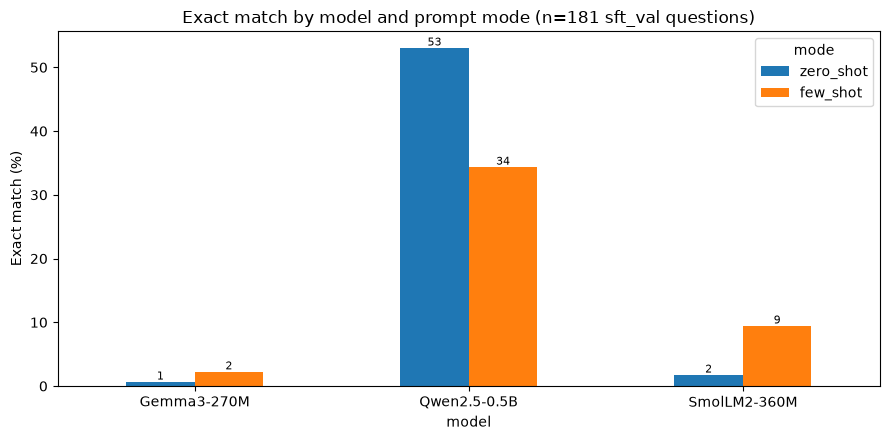

In [17]:
pivot = summary.pivot(index="model", columns="mode", values="exact_match")[PROMPT_MODES]

ax = pivot.plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.set_ylabel("Exact match (%)")
ax.set_title(f"Exact match by model and prompt mode (n={len(eval_records)} sft_val questions)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8)
plt.tight_layout()
plt.show()

### Model specs
Facts about each model that matter beyond accuracy: size, how long its context can be, how much of your 6 GB it used, and the license.

In [18]:
specs_df.join(
    summary[summary["mode"] == "zero_shot"].set_index("model")[["prompt_tokens"]]
    .rename(columns={"prompt_tokens": "avg_prompt_tokens_zero_shot"})
)

,model_id,params_millions,context_length,dtype,peak_vram_gb,license,run_config,avg_prompt_tokens_zero_shot
model,,,,,,,,
SmolLM2-360M,HuggingFaceTB/SmolLM2-360M-Instruct,362,8192,torch.bfloat16,1.27,Apache-2.0,7bb5713461ed,525.00
Qwen2.5-0.5B,Qwen/Qwen2.5-0.5B-Instruct,494,32768,torch.bfloat16,1.38,Apache-2.0,7bb5713461ed,482.45
Gemma3-270M,google/gemma-3-270m-it,268,32768,torch.bfloat16,0.74,Gemma Terms of Use,7bb5713461ed,547.10


### Scores per dataset feature (few-shot, exact match %)
This is where the real differences show. E.g. a model that's fine on `single` but collapses on `multi_distinct_tools` will struggle with 50% of the training data.

In [19]:
few = benchmark_df[benchmark_df["mode"] == "few_shot"]

for feature in FEATURE_COLS:
    table = (few.pivot_table(index="model", columns=feature, values="exact_match", aggfunc="mean") * 100).round(1)
    counts = few[few["model"] == few["model"].iloc[0]][feature].value_counts()
    table.columns = [f"{c} (n={counts.get(c, 0)})" for c in table.columns]
    print(f"\n=== {feature} ===")
    display(table)


=== call_pattern ===


,mixed (n=31),multi_distinct_tools (n=50),parallel_same_tool (n=50),single (n=50)
model,,,,
Gemma3-270M,0.0,2.0,4.0,2.0
Qwen2.5-0.5B,9.7,20.0,48.0,50.0
SmolLM2-360M,0.0,6.0,4.0,24.0



=== calls_bucket ===


,1 (n=50),2 (n=81),3 (n=33),4+ (n=17)
model,,,,
Gemma3-270M,2.0,2.5,3.0,0.0
Qwen2.5-0.5B,50.0,34.6,21.2,11.8
SmolLM2-360M,24.0,6.2,0.0,0.0



=== tools_bucket ===


,1 (n=46),2-3 (n=97),4+ (n=38)
model,,,
Gemma3-270M,4.3,1.0,2.6
Qwen2.5-0.5B,56.5,24.7,31.6
SmolLM2-360M,15.2,4.1,15.8



=== arg_complexity ===


,scalar (n=163),structured (n=18)
model,,
Gemma3-270M,1.8,5.6
Qwen2.5-0.5B,33.1,44.4
SmolLM2-360M,9.8,5.6



=== has_optional ===


,no (n=26),yes (n=155)
model,,
Gemma3-270M,3.8,1.9
Qwen2.5-0.5B,61.5,29.7
SmolLM2-360M,19.2,7.7


### How do they fail? (% of questions, few-shot)
How a model fails tells you more than the score. `parse_fail` / `invented_tool` = can't follow the format (SFT fixes this easily). `wrong_tool` / `wrong_value` = understanding errors (harder to fix).

In [20]:
FAILURE_ORDER = ["correct", "parse_fail", "invented_tool", "wrong_call_count", "wrong_tool",
                 "missing_required_arg", "unknown_arg", "wrong_value"]

failures = (pd.crosstab(few["model"], few["failure_type"], normalize="index") * 100).round(1)
failures[[c for c in FAILURE_ORDER if c in failures.columns]]

failure_type,correct,parse_fail,invented_tool,wrong_call_count,wrong_tool,missing_required_arg,unknown_arg,wrong_value
model,,,,,,,,
Gemma3-270M,2.2,29.3,18.8,30.9,3.3,4.4,0.6,10.5
Qwen2.5-0.5B,34.3,19.3,0.6,16.0,3.3,0.0,3.9,22.7
SmolLM2-360M,9.4,8.8,1.1,54.1,8.8,1.1,3.9,12.7


In [21]:
# eyeball a few raw failures per model to make sure the scorer isn't being unfair
for model_name, group in few[few["failure_type"] != "correct"].groupby("model"):
    print(f"\n##### {model_name}")
    for _, row in group.head(2).iterrows():
        print(f"[{row['failure_type']}] {str(row['raw_response'])[:300]!r}")


##### Gemma3-270M
[wrong_call_count] '```json\n[\n  {\n    "name": "get_scrabble_score",\n    "description": "Fetches the Scrabble score for \'data\' and \'science\'.",\n    "parameters": {\n      "mot": {\n        "description": "The word for which the Scrabble score is to be retrieved.",\n        "type": "str",\n        "default": "cheval"\n      }'
[wrong_call_count] '```json\n[\n  {\n    "name": "dns",\n    "description": "Fetches DNS records for a given domain using the RapidAPI domain checker service.",\n    "parameters": {\n      "domain": {\n        "description": "The domain for which DNS records are to be retrieved.",\n        "type": "str",\n        "default": "ra'

##### Qwen2.5-0.5B
[parse_fail] '[{"name": "get_scrabble_score", "arguments": {"mot": "data"}}, {"name": "get_scrabble_score", "arguments": {"mot": "science"}}],\n["get_breed_information", {"breed": "Bengal"}], [{"name": "property_details", "arguments": {"property_id": "456 Elm St"}, "address": "456 Elm St"}]]'


## Save the summary

In [22]:
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
specs_df.to_csv(RESULTS_DIR / "model_specs.csv")

selection_report = {
    "data": str(VAL_PATH),
    "n_questions": len(eval_records),
    "seed": SEED,
    "prompt_modes": PROMPT_MODES,
    "few_shot_ids": [ex["id"] for ex in few_shot_examples],
    "max_new_tokens": MAX_NEW_TOKENS,
    "few_shot_exact_match": pivot["few_shot"].to_dict(),
    "zero_shot_exact_match": pivot["zero_shot"].to_dict(),
}
(RESULTS_DIR / "selection_report.json").write_text(json.dumps(selection_report, indent=2))
print(f"Saved summary, specs and report to {RESULTS_DIR}")

Saved summary, specs and report to data\reports\model_selection


## How to decide
1. **Drop the clear losers.** Any model that still has lots of `parse_fail` / `invented_tool` *in few-shot mode* can't even follow the format when shown it.
2. **Compare few-shot exact match, but respect the noise.** With ~180 questions, differences under ~7 points are within noise. Treat those models as tied.
3. **Break ties with the feature tables and specs:** multi-call performance (half the dataset), fewer prompt tokens (cheaper fine-tuning on 6 GB), license.
4. **Shortlist the top 2 → pilot fine-tune each** (same LoRA settings, ~2k examples, a few hundred steps) and score on `sft_val` again. *That* picks the final model, because it measures how well each one learns your task.

Record the zero-shot numbers of the final pick: they're the **baseline** in the README's "base → SFT → DPO" table (re-run on the frozen test set at the end).